# Semana 4: Hodgkin-Huxley: ecuaciones y canales

**Objetivo:** relacionar cada corriente iónica con una fase del potencial de acción y
predecir qué ocurre al bloquear parcialmente Na⁺ o K⁺.

## Modelo

$$C_m \frac{dV}{dt} = I_\text{ext} - \underbrace{\bar g_\text{Na}\, m^3 h\,(V - E_\text{Na})}_{I_\text{Na}}
  - \underbrace{\bar g_\text{K}\, n^4\,(V - E_\text{K})}_{I_\text{K}}
  - \underbrace{g_L\,(V - E_L)}_{I_L}$$

$$\frac{dx}{dt} = \alpha_x(V)\,(1 - x) - \beta_x(V)\,x, \qquad x \in \{m, h, n\}$$

| Parámetro | Valor | Papel |
|---|---|---|
| $\bar g_\text{Na}$, $E_\text{Na}$ | 120 mS/cm², +50 mV | despolarización rápida (subida) |
| $\bar g_\text{K}$, $E_\text{K}$ | 36 mS/cm², −77 mV | repolarización (bajada) |
| $g_L$, $E_L$ | 0.3 mS/cm², −54.4 mV | fuga pasiva |
| $C_m$ | 1 µF/cm² | capacitancia |

## Diseño del experimento

Un bloqueo cambia el **potencial de reposo**. Si cada condición empieza en −65 mV, parte de la
respuesta es solo la relajación hacia el nuevo reposo, no el efecto del estímulo. Por eso,
antes de estimular, cada condición se deja evolucionar 300 ms sin corriente y se usa su
voltaje final como reposo. El estímulo es un pulso de 20 µA/cm² entre 5 y 6 ms.

Sin potasio **no existe** un reposo cercano a −65 mV: el único equilibrio está cerca de 0 mV
(bloqueo por despolarización). Esa condición se muestra aparte, en línea discontinua.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from computational_neuroscience import current_pulse, simulate_hodgkin_huxley
from computational_neuroscience.outputs import save_data, save_figure

WEEK = 4
DT_MS = 0.01
DURATION_MS = 40.0
time = np.arange(0.0, DURATION_MS + DT_MS / 2, DT_MS)
stimulus = current_pulse(time, 20.0, 5.0, 6.0)


def resting_voltage(**conductances: float) -> float:
    """Voltage after 300 ms without input, starting from -65 mV."""
    settle = simulate_hodgkin_huxley(0.0, duration_ms=300.0, dt_ms=DT_MS, **conductances)
    return float(settle.voltage_mv[-1])


def stimulated(**conductances: float):
    rest = resting_voltage(**conductances)
    return rest, simulate_hodgkin_huxley(
        stimulus, duration_ms=DURATION_MS, dt_ms=DT_MS, initial_voltage_mv=rest, **conductances
    )


sodium_conditions = {"Control (gNa=120)": 120.0, "gNa 50% (60)": 60.0, "gNa blocked (0)": 0.0}
potassium_conditions = {"Control (gK=36)": 36.0, "gK 67% (24)": 24.0}
sodium_results = {label: stimulated(sodium_conductance_ms_cm2=g) for label, g in sodium_conditions.items()}
potassium_results = {label: stimulated(potassium_conductance_ms_cm2=g) for label, g in potassium_conditions.items()}
no_potassium = simulate_hodgkin_huxley(stimulus, duration_ms=DURATION_MS, dt_ms=DT_MS, potassium_conductance_ms_cm2=0.0)
no_potassium_rest = resting_voltage(potassium_conductance_ms_cm2=0.0)

## Figura

Izquierda: bloqueo de Na⁺. Derecha: reducción de K⁺, y en discontinua el caso sin K⁺, que parte
de −65 mV pero no tiene reposo estable allí. La franja gris marca el pulso de estímulo.

Saved: weeks/week_04_hh_channels/outputs/hh_channel_block.png
Saved: weeks/week_04_hh_channels/outputs/hh_channel_block.npz


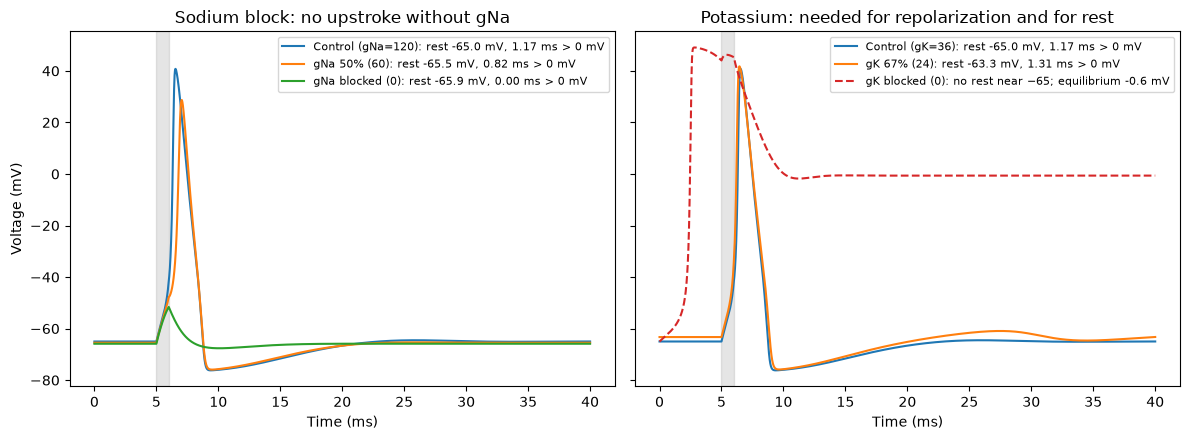

In [2]:
figure, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for axis, results, title in (
    (axes[0], sodium_results, "Sodium block: no upstroke without gNa"),
    (axes[1], potassium_results, "Potassium: needed for repolarization and for rest"),
):
    axis.axvspan(5.0, 6.0, color="grey", alpha=0.2)
    for label, (rest, result) in results.items():
        width = np.sum(result.voltage_mv > 0.0) * DT_MS
        axis.plot(result.time_ms, result.voltage_mv, label=f"{label}: rest {rest:.1f} mV, {width:.2f} ms > 0 mV")
    axis.set(xlabel="Time (ms)", title=title)
axes[1].plot(no_potassium.time_ms, no_potassium.voltage_mv, "--", color="tab:red",
             label=f"gK blocked (0): no rest near −65; equilibrium {no_potassium_rest:.1f} mV")
axes[0].set_ylabel("Voltage (mV)")
for axis in axes:
    axis.legend(fontsize=8, loc="upper right")
save_figure(WEEK, figure, "hh_channel_block.png")
save_data(
    WEEK, "hh_channel_block.npz", time_ms=time, stimulus_ua_cm2=stimulus,
    **{f"na_{g:g}": r.voltage_mv for g, (_, r) in zip(sodium_conditions.values(), sodium_results.values())},
    **{f"k_{g:g}": r.voltage_mv for g, (_, r) in zip(potassium_conditions.values(), potassium_results.values())},
    k_0_from_minus65=no_potassium.voltage_mv,
)

## Validación

- El control reposa en −65 mV y dispara un potencial de acción (pico > 0 mV) tras el pulso.
- Sin Na⁺ no hay potencial de acción: solo una despolarización pasiva.
- Con 50 % de Na⁺ el pico es más bajo que en el control.
- Con menos K⁺ el potencial de acción dura más (más tiempo por encima de 0 mV).
- Sin K⁺ el equilibrio en reposo está despolarizado (> −20 mV).

In [3]:
def width_above_zero(result) -> float:
    return float(np.sum(result.voltage_mv > 0.0) * DT_MS)


control_rest, control = sodium_results["Control (gNa=120)"]
_, half_sodium = sodium_results["gNa 50% (60)"]
_, no_sodium = sodium_results["gNa blocked (0)"]
_, reduced_potassium = potassium_results["gK 67% (24)"]
assert abs(control_rest + 65.0) < 0.1
assert control.voltage_mv.max() > 0.0
assert no_sodium.voltage_mv.max() < -40.0
assert half_sodium.voltage_mv.max() < control.voltage_mv.max()
assert width_above_zero(reduced_potassium) > width_above_zero(control)
assert no_potassium_rest > -20.0
print(f"Peaks (mV): control {control.voltage_mv.max():.1f}, gNa 50% {half_sodium.voltage_mv.max():.1f}, gNa 0 {no_sodium.voltage_mv.max():.1f}")
print(f"Width above 0 mV (ms): control {width_above_zero(control):.2f}, gK 67% {width_above_zero(reduced_potassium):.2f}")
print(f"Equilibrium without gK: {no_potassium_rest:.1f} mV")

Peaks (mV): control 40.8, gNa 50% 28.7, gNa 0 -51.6
Width above 0 mV (ms): control 1.17, gK 67% 1.31
Equilibrium without gK: -0.6 mV


## Interpretación y límites

- $I_\text{Na}$ produce la subida: sin ella el pulso solo carga la membrana pasivamente.
- $I_\text{K}$ produce la bajada y mantiene el reposo. Reducirla al 67 % solo alarga el spike
  ~10 % (el resto de $\bar g_\text{K}$ basta para repolarizar), pero quitarla del todo deja la
  membrana despolarizada y no excitable.
- Reducir K⁺ a ~60 % o menos hace que el modelo dispare espontáneamente: la frontera entre
  reposo y actividad repetitiva depende del balance Na⁺/K⁺.
- Es el modelo del axón gigante de calamar a 6.3 °C; otras neuronas tienen más tipos de canales.

**Para tu entrega:** dibuja las ecuaciones anotadas con unidades y escribe tu predicción
antes de cambiar `potassium_conductance_ms_cm2` a 30 y 21.